<a href="https://colab.research.google.com/github/sabrina-cortes/Metodos-Numericos-FIS1344-TAREAS/blob/main/Tarea_8.10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Tarea 8.10: Métodos de Taylor

Enunciado:
Considere el problema de valor inicial

$$
y'(t)=-10y,
\qquad
0\leq t\leq2,
\qquad
y(0)=1.
$$

La solución exacta es

$$
y(t)=e^{-10t}.
$$

**¿Qué ocurre cuando el método de Euler se aplica a este problema con $h=0.1$?**

**¿Viola la fórmula del error del método?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt

El método de Euler está dado por

$$
w_{i+1}=w_i+h f(t_i,w_i).
$$

En este caso,

$$
f(t,y)=-10y,
$$

por lo que

$$
w_{i+1}=w_i-10h\,w_i.
$$

Para $h=0.1$:

$$
w_{i+1}=w_i-w_i=0.
$$

Por lo tanto, después del primer paso todas las aproximaciones son cero.

In [3]:
def euler(f, a, b, yo, N):

    h = (b-a)/N
    t = a
    w = yo

    ts = np.zeros(N+1)
    sol = np.zeros(N+1)

    for i in range(N):
        ts[i] = t
        sol[i] = w

        w = w + h*f(t, w)
        t = t + h

    ts[N] = t
    sol[N] = w

    return ts, sol

In [4]:
#Definimos la ecuación
def f(t, y):
    return -10*y

N = 20

ts, aprox = euler(f, 0, 2, 1, N)

print(aprox)

[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


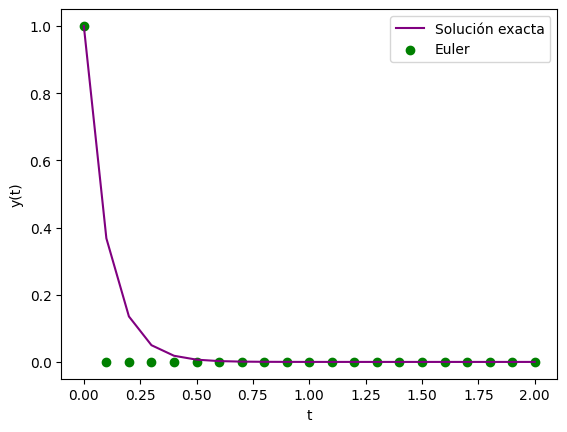

In [5]:
#Comparamos
exacta = np.exp(-10*ts)

plt.plot(ts, exacta, color="purple" ,label="Solución exacta")
plt.scatter(ts, aprox, color="green" ,label="Euler")

plt.xlabel("t")
plt.ylabel("y(t)")
plt.legend()
plt.show()

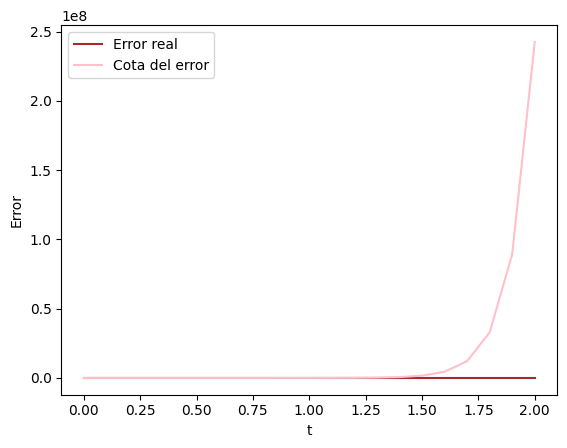

In [6]:
#Verificamos la cota
h = 0.1
L = 10
M = 100

error_real = np.abs(exacta - aprox)

cota = h*M/(2*L) * (np.exp(L*ts) - 1)

plt.plot(ts, error_real, color="brown" ,label="Error real")
plt.plot(ts, cota, color="pink" ,label="Cota del error")

plt.xlabel("t")
plt.ylabel("Error")
plt.legend()
plt.show()

## Conclusión

Al aplicar el método de Euler con $h=0.1$ al problema

$$
y'=-10y,
$$

se obtiene

$$
w_{i+1}=w_i-10(0.1)w_i=0.
$$

Por esta razón, después del primer paso todas las aproximaciones numéricas son iguales a cero, mientras que la solución exacta

$$
y(t)=e^{-10t}
$$

permanece positiva.

Sin embargo, este comportamiento no viola la fórmula de error del método de Euler. La cota teórica sigue siendo mayor que el error real, aunque resulta bastante conservadora y crece rápidamente al alejarnos del punto inicial.

## Nota: 7.0

Base: 1/1; funcionamiento: 4/4; comentarios: 1/1; claridad: 1/1.
